In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
belief_col = "Belief_opinion_on_january_6th_storming_of_the_us_capitol_Symbol"

In [3]:
state_preds = pd.read_csv(f'/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Dropped_ICAR_MrP/{belief_col}_stan_output/state_level_predictions.csv')

In [4]:
state_preds.head()

,state_idx,pred_mean,pred_median,pred_lower,pred_upper,pred_sd,n_cells,n_draws,n_weight_samples
0,1,1.427304,1.423100,1.274436,1.607801,0.082856,2160,8000,104
1,2,1.494282,1.489629,1.423808,1.587394,0.041846,2160,8000,104
2,3,1.459254,1.458721,1.392751,1.531801,0.035003,2160,8000,104
3,4,1.403680,1.404251,1.351088,1.454712,0.026163,2160,8000,104
4,5,1.291032,1.290946,1.261110,1.321111,0.015410,2160,8000,104


In [5]:
raw_df = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/drop_usa_cleaned_all_result.csv")

In [6]:
raw_df.head()

,Unnamed: 0,id,time_window_start,tweets_struct,name,username,description,location,public_metrics.followers_count,profile_image_url,...,Belief_opinion_on_whether_the_tone_of_political_discourse_in_the_u_s_has_become_more_factbased_Symbol_cat,Belief_opinion_on_whether_the_tone_of_political_discourse_in_the_u_s_has_become_more_factbased_Symbol_num,Belief_opinion_on_the_statement_elected_officials_using_heated_or_aggressive_language_to_talk_about_certain_people_or_groups_makes_violence_against_those_groups_more_likely_Symbol_cat,Belief_opinion_on_the_statement_elected_officials_using_heated_or_aggressive_language_to_talk_about_certain_people_or_groups_makes_violence_against_those_groups_more_likely_Symbol_num,Demo_sex_idx,Demo_age_idx,Demo_ethnicity_idx,Demo_income_idx,Demo_past_vote_idx,state_cleaned_idx
0,0,1081532502966239232,2023-11-05 00:00:00+00:00,[],caleb ❍,xxaleb,"i think a lot, listen to music. i’m fond of fl...",they/he ☆ 20,4426,https://pbs.twimg.com/profile_images/180336437...,...,NaN,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1081532502966239232,2023-11-19 00:00:00+00:00,[],caleb ❍,xxaleb,"i think a lot, listen to music. i’m fond of fl...",they/he ☆ 20,4426,https://pbs.twimg.com/profile_images/180336437...,...,NaN,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1081532502966239232,2023-12-03 00:00:00+00:00,[],caleb ❍,xxaleb,"i think a lot, listen to music. i’m fond of fl...",they/he ☆ 20,4426,https://pbs.twimg.com/profile_images/180336437...,...,NaN,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1081532502966239232,2023-12-17 00:00:00+00:00,[],caleb ❍,xxaleb,"i think a lot, listen to music. i’m fond of fl...",they/he ☆ 20,4426,https://pbs.twimg.com/profile_images/180336437...,...,NaN,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
4,4,1081532502966239232,2023-12-31 00:00:00+00:00,[],caleb ❍,xxaleb,"i think a lot, listen to music. i’m fond of fl...",they/he ☆ 20,4426,https://pbs.twimg.com/profile_images/180336437...,...,NaN,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
raw_df["Demo_past_vote_idx"].unique()

array([nan,  1.,  2.,  3.,  6.,  4.,  5.])

In [8]:
state_mapping = raw_df[['state_cleaned_idx', 'state_cleaned']].drop_duplicates().sort_values('state_cleaned_idx')
state_mapping_dict = dict(zip(state_mapping['state_cleaned_idx'], state_mapping['state_cleaned']))

state_preds['state_cleaned'] = state_preds['state_idx'].map(state_mapping_dict)

In [9]:
print(raw_df.columns.tolist())

['Unnamed: 0', 'id', 'time_window_start', 'tweets_struct', 'name', 'username', 'description', 'location', 'public_metrics.followers_count', 'profile_image_url', 'clean...pool', 'is_empty_window', 'window_weeks_to_election', 'profile_image_description', 'profile_image_main_info', 'Model', 'Belief_Raw', 'Belief_Cleaned', 'Demo_Raw', 'Demo_Cleaned', 'Belief_opinion_on_the_number_of_immigrants_in_america_Category', 'Belief_opinion_on_the_number_of_immigrants_in_america_Explanation', 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol', 'Belief_opinion_on_the_number_of_immigrants_in_america_Speculation', 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Category', 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Explanation', 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Symbol', 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Speculation', 'Belief_opinion_on_the_statement_immigrants_take_jobs_away_from_people_who_

In [10]:
print(len(raw_df["state_cleaned"].unique()))

49


In [11]:
print(raw_df["Demo_partisan_loyalties_Symbol"].value_counts())

Demo_partisan_loyalties_Symbol
pid7    2605
pid4    2219
pid3    1101
pid1     879
pid5     410
pid6     109
pid2      57
Name: count, dtype: int64


In [12]:
print(raw_df["Demo_past_vote_Symbol"].value_counts())

Demo_past_vote_Symbol
vpa2    3353
vpa3    2614
vpa1    1280
vpa6     106
vpa4      15
vpa5      12
Name: count, dtype: int64


In [13]:
raw_df = raw_df.dropna(subset=["state_cleaned"])

# state map comparison

In [14]:
raw_state = (raw_df.groupby("state_cleaned")[belief_col+"_num"].mean().reset_index().rename(columns={belief_col+"_num": "raw_mean"}))

In [15]:
# Load shapefile
shp = gpd.read_file("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp")
shp['STATE'] = shp['STUSPS']


In [16]:
state_map = raw_state.merge(state_preds, left_on='state_cleaned', right_on='state_cleaned')
state_map.head()

,state_cleaned,raw_mean,state_idx,pred_mean,pred_median,pred_lower,pred_upper,pred_sd,n_cells,n_draws,n_weight_samples
0,AL,1.796296,2,1.494282,1.489629,1.423808,1.587394,0.041846,2160,8000,104
1,AR,1.738095,3,1.459254,1.458721,1.392751,1.531801,0.035003,2160,8000,104
2,AZ,1.401826,4,1.403680,1.404251,1.351088,1.454712,0.026163,2160,8000,104
3,CA,1.369565,5,1.291032,1.290946,1.261110,1.321111,0.015410,2160,8000,104
4,CO,1.478723,6,1.400261,1.399889,1.352975,1.449948,0.024404,2160,8000,104


In [17]:
map_df = shp.merge(state_map, left_on="STATE", right_on = "state_cleaned")


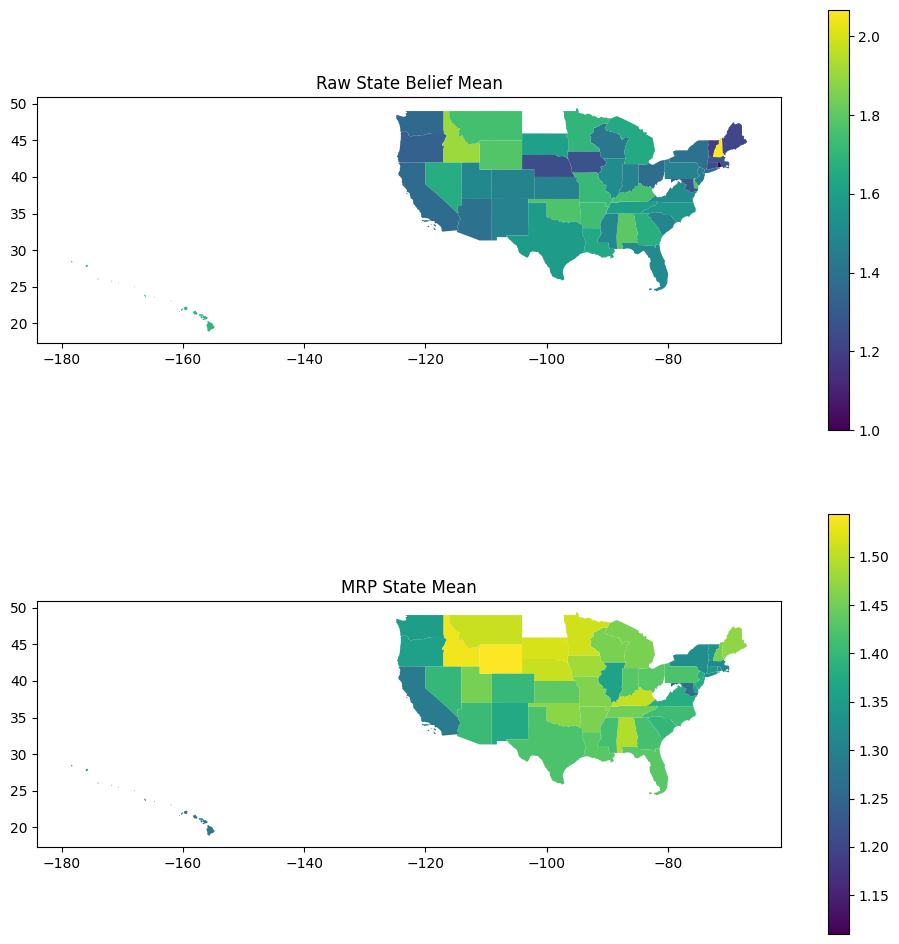

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

map_df.plot(column="raw_mean", cmap="viridis", legend=True, ax=axes[0])
axes[0].set_title("Raw State Belief Mean")

map_df.plot(column="pred_mean", cmap="viridis", legend=True, ax=axes[1])
axes[1].set_title("MRP State Mean")

plt.show()

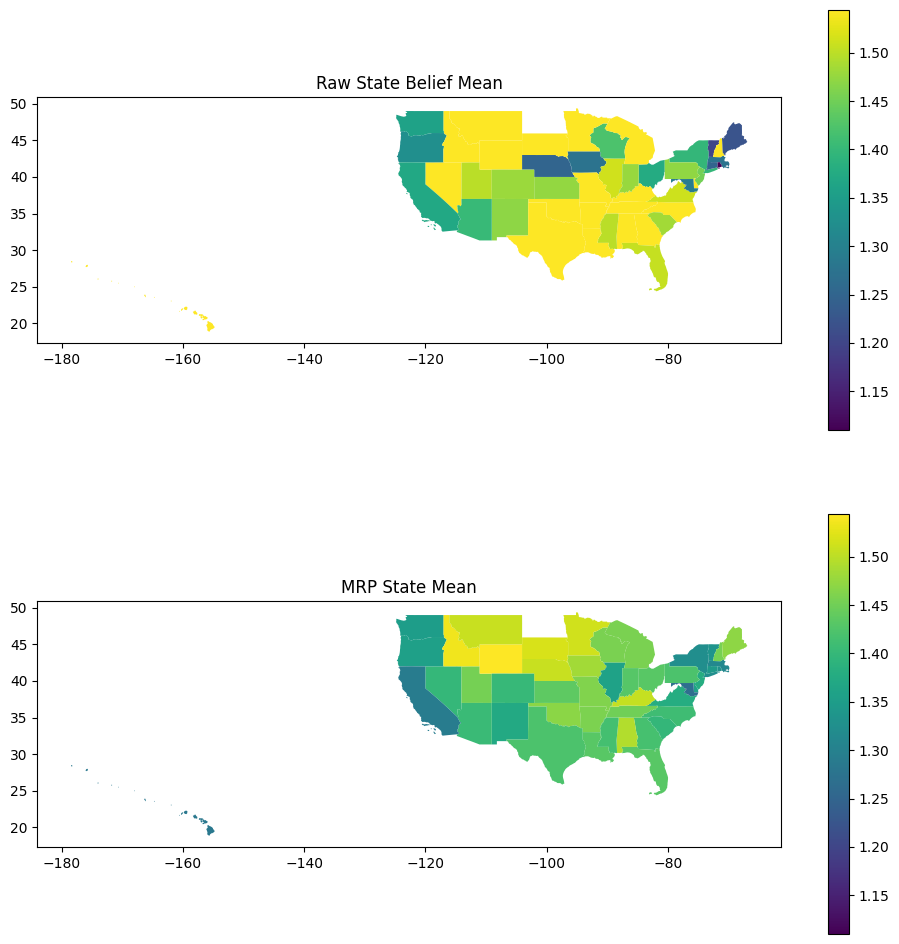

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

vmin = map_df["pred_mean"].min()
vmax = map_df["pred_mean"].max()

map_df.plot(column="raw_mean", cmap="viridis", legend=True, ax=axes[0], vmin=vmin, vmax=vmax)
axes[0].set_title("Raw State Belief Mean")

map_df.plot(column="pred_mean", cmap="viridis", legend=True, ax=axes[1], vmin=vmin, vmax=vmax)
axes[1].set_title("MRP State Mean")

plt.show()

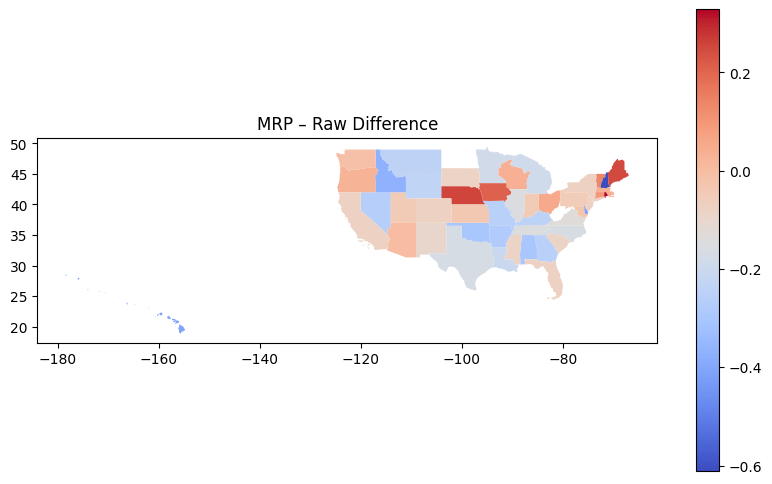

In [20]:
map_df["diff"] = map_df["pred_mean"] - map_df["raw_mean"]
map_df.plot(column="diff", cmap="coolwarm", legend=True, figsize=(10,6))
plt.title("MRP – Raw Difference")
plt.show()


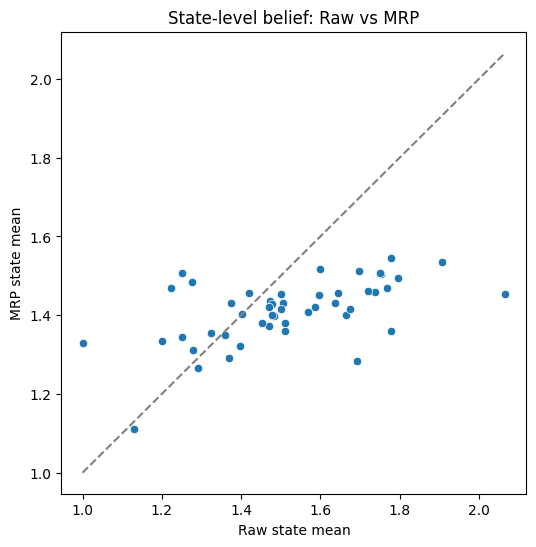

In [21]:
plt.figure(figsize=(6,6))
sns.scatterplot(data=map_df, x="raw_mean", y="pred_mean")

lims = [
    min(map_df[["raw_mean","pred_mean"]].min()),
    max(map_df[["raw_mean","pred_mean"]].max())
]
plt.plot(lims, lims, "--", color="gray")
plt.xlabel("Raw state mean")
plt.ylabel("MRP state mean")
plt.title("State-level belief: Raw vs MRP")
plt.show()


In [22]:
print(map_df["raw_mean"].corr(map_df["pred_mean"]))

0.5530658621632829


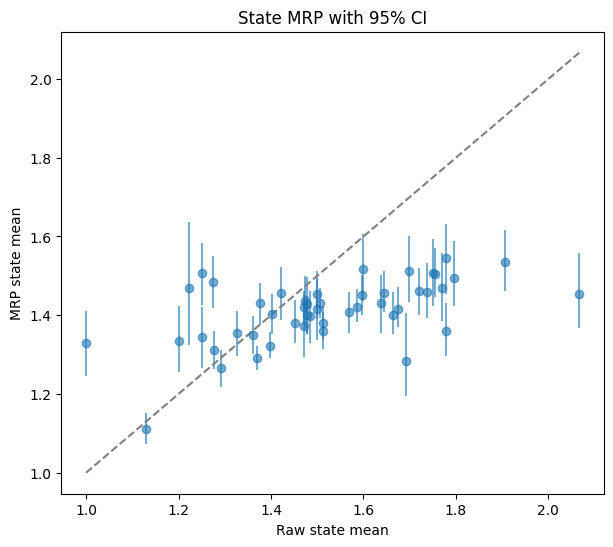

In [23]:
plt.figure(figsize=(7,6))
plt.errorbar(
    map_df["raw_mean"],
    map_df["pred_mean"],
    yerr=[
        map_df["pred_mean"] - map_df["pred_lower"],
        map_df["pred_upper"] - map_df["pred_mean"]
    ],
    fmt="o",
    alpha=0.6
)
plt.plot(lims, lims, "--", color="gray")
plt.xlabel("Raw state mean")
plt.ylabel("MRP state mean")
plt.title("State MRP with 95% CI")
plt.show()